# Identyfikacja wzorców i anomalii w deformacjach terenu na podstawie danych EGMS

## Cel ćwiczenia

W ćwiczeniu analizujemy szeregi czasowe przemieszczeń punktów PS-InSAR pochodzących z danych EGMS. Celem jest rozpoznanie różnych sposobów zachowania punktów w czasie oraz wskazanie tych, których przebieg deformacji różni się od typowego zachowania obserwowanego w analizowanym zbiorze.

Analiza ma odpowiedzieć na dwa główne pytania:

1. **Które punkty PS wykazują nietypowe zachowanie deformacyjne?**
Do ich identyfikacji wykorzystamy metodę Isolation Forest, która pozwala wskazać obserwacje różniące się od większości punktów pod względem analizowanych cech szeregu czasowego.

2. **Jakie typowe wzorce zachowania występują wśród punktów PS?**
Za pomocą metody K-means pogrupujemy punkty o podobnych charakterystykach deformacji i porównamy przebieg ich szeregów czasowych.



EGMS: https://egms.land.copernicus.eu/

Budynki: https://eubucco.com/data/download/v0.2

Dokumentacja: https://land.copernicus.eu/en/products/european-ground-motion-service?tab=documentation

# ETAP 1 — Import i kontrola danych





In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [19]:
df = pd.read_csv("thessaloniki_points.csv")

df = df.rename(columns={
    "height_ort": "height_ortho",
    "mean_veloc": "mean_velocity",
    "mean_vel_1": "mean_velocity_std",
    "accelerati": "acceleration",
    "accelera_1": "acceleration_std",
    "seasonalit": "seasonality",
    "seasonal_1": "seasonality_std",
    "gnss_veloc": "gnss_velocity_n",
    "gnss_vel_1": "gnss_velocity_e",
    "gnss_vel_2": "gnss_velocity_u"
})

print("Liczba punktów PS:", len(df))
print("Liczba wszystkich kolumn:", len(df.columns))
df.head()


Liczba punktów PS: 5625
Liczba wszystkich kolumn: 317


,pid,easting,northing,height_ortho,rmse_ts,mean_velocity,mean_velocity_std,acceleration,acceleration_std,seasonality,...,20241026,20241101,20241107,20241113,20241119,20241125,20241201,20241207,20241213,20241219
0,10Oj6Do6NR,5414950,2027550,9.1,0.5,-2.5,0.0,0.16,0.03,0.3,...,-13.4,-13.2,-12.5,-12.4,-12.9,-12.7,-12.2,-12.5,-13.2,-13.2
1,10Oj6Do6NS,5415050,2027550,11.2,0.6,-2.3,0.0,0.45,0.04,0.5,...,-10.4,-10.4,-9.8,-9.7,-10.8,-11.2,-10.7,-10.3,-10.7,-10.9
2,10Oj6Do6NT,5415150,2027550,12.6,0.6,-2.6,0.0,0.49,0.04,0.3,...,-12.3,-12.4,-12.0,-11.7,-12.9,-13.2,-13.8,-13.7,-12.7,-12.7
3,10Oj6Do6NU,5415250,2027550,12.1,0.5,-3.0,0.0,0.55,0.03,0.5,...,-14.3,-14.3,-13.7,-13.8,-13.5,-13.0,-15.0,-15.0,-13.9,-14.1
4,10Oj6Do6NV,5415350,2027550,16.8,0.7,-3.6,0.0,0.74,0.04,0.5,...,-16.8,-17.1,-17.1,-17.3,-17.5,-17.5,-17.4,-17.6,-17.7,-17.7


In [20]:
date_cols = [
    col for col in df.columns
    if str(col).isdigit() and len(str(col)) == 8
]

dates = pd.to_datetime(date_cols, format="%Y%m%d")


print("Liczba punktów PS:", len(df))
print("Liczba obserwacji czasowych:", len(date_cols))
print("Pierwsza obserwacja:", dates.min().date())
print("Ostatnia obserwacja:", dates.max().date())
print("Braki w szeregu czasowym:", df[date_cols].isna().sum().sum())

Liczba punktów PS: 5625
Liczba obserwacji czasowych: 303
Pierwsza obserwacja: 2020-01-03
Ostatnia obserwacja: 2024-12-19
Braki w szeregu czasowym: 0


## Podstawowe parametry EGMS

Przegląd parametrów dostarczonych wraz z danymi. Szczególnie ważne są:

- `mean_velocity` — średnia prędkość przemieszczenia,
- `acceleration` — informacja o zmianie prędkości,
- `seasonality` — amplituda zachowania sezonowego,
- `rmse_ts` — parametr jakości/rozrzutu dopasowania szeregu.



In [21]:
basic_features = ["mean_velocity", "acceleration", "seasonality", "rmse_ts"]
df[basic_features].describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
mean_velocity,5625.0,-2.945,3.617,-26.90,-3.40,-1.60,-0.80,2.70
acceleration,5625.0,0.281,0.813,-3.88,-0.18,0.17,0.67,5.58
seasonality,5625.0,1.500,1.389,0.00,0.70,1.10,1.80,15.50
rmse_ts,5625.0,1.296,0.747,0.30,0.70,1.10,1.70,4.30


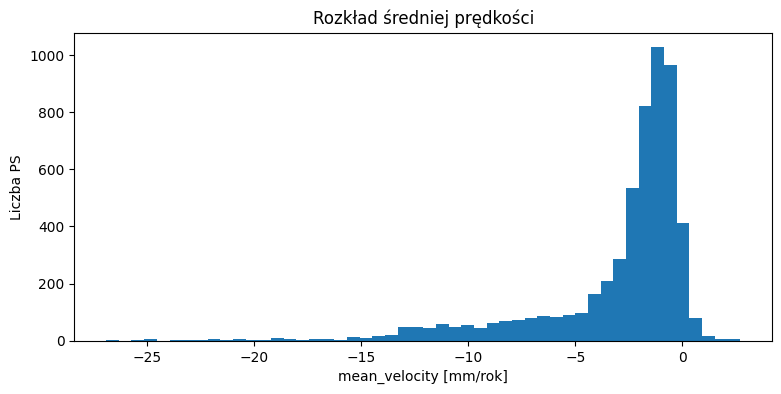

In [22]:
plt.figure(figsize=(9, 4))
plt.hist(df["mean_velocity"], bins=50)
plt.xlabel("mean_velocity [mm/rok]")
plt.ylabel("Liczba PS")
plt.title("Rozkład średniej prędkości")
plt.show()


## Oglądanie pojedynczego szeregu czasowego

Funkcja `plot_ps()` będzie również używana później do kontroli punktów wskazanych przez model.


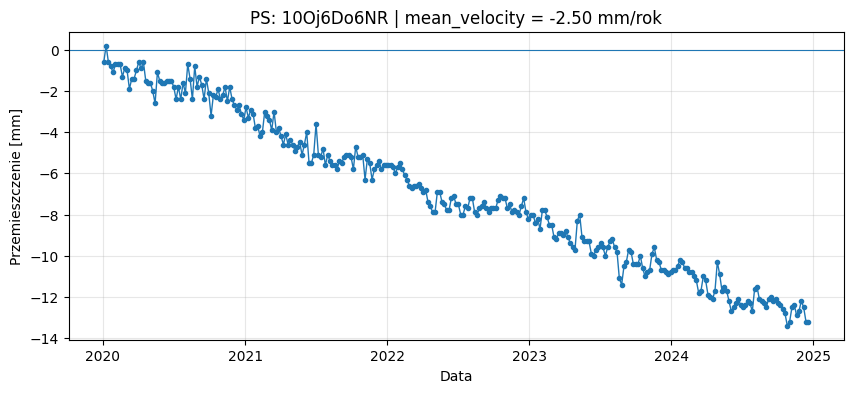

In [23]:
def plot_ps(pid):
    row = df[df["pid"] == pid].iloc[0]
    y = row[date_cols].astype(float).values

    plt.figure(figsize=(10, 4))
    plt.plot(dates, y, marker=".", linewidth=1)
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Data")
    plt.ylabel("Przemieszczenie [mm]")
    plt.title(
        f"PS: {pid} | mean_velocity = {row['mean_velocity']:.2f} mm/rok"
    )
    plt.grid(alpha=0.3)
    plt.show()

plot_ps(df.iloc[0]["pid"])


# ETAP 2 — Zamiana szeregu czasowego na informacje

Model nie otrzymuje całego szeregu 303 obserwacji bezpośrednio. Najpierw musimy stworzyć kilka **interpretowalnych cech**, które opisują zachowanie punktu PS. W ML nazywamy to **feature engineeringiem**.

In [24]:
# Rzeczywisty czas w latach od pierwszej obserwacji.
# Dzięki temu regresja uwzględnia faktyczne odstępy między datami.
time_years = ((dates - dates.min()).days / 365.25).to_numpy()

# Tworzymy funkcję do wyznaczania trendu liniowego dla dowolnego fragmentu szeregu czasowego.
# Nachylenie trendu (slope) jest wyrażone w mm/rok. Dla całego szeregu opisuje długookresowe tempo
# zmian i może być zbliżone do mean_velocity dostarczonego przez EGMS. Funkcja będzie jednak
# potrzebna przede wszystkim do porównywania trendów wyznaczonych dla różnych okresów oraz do oceny
# ich regularności za pomocą R².

def fit_linear_trend(values, time_values):
    y = np.asarray(values, dtype=float)
    t = np.asarray(time_values, dtype=float)

    mask = np.isfinite(y) & np.isfinite(t)
    y = y[mask]
    t = t[mask]

    if len(y) < 3 or np.unique(t).size < 2:
        return np.nan, np.nan

    model = LinearRegression()
    model.fit(t.reshape(-1, 1), y)

    slope = model.coef_[0]
    r2 = model.score(t.reshape(-1, 1), y)

    return slope, r2

## 2A. Trend całego okresu

`trend` jest nachyleniem regresji liniowej dopasowanej do **wszystkich obserwacji** punktu PS i ma jednostkę mm/rok.

`trend_R2` informuje, jak dobrze prosty trend liniowy opisuje cały przebieg. Niskie `R²` nie oznacza automatycznie błędnych danych — przebieg może być nieliniowy lub zmienny w czasie.


In [25]:
global_results = df.apply(
    lambda row: fit_linear_trend(row[date_cols].values, time_years),
    axis=1
)

df["trend"] = [x[0] for x in global_results]
df["trend_R2"] = [x[1] for x in global_results]

df[["pid", "mean_velocity", "trend", "trend_R2"]].head()


,pid,mean_velocity,trend,trend_R2
0,10Oj6Do6NR,-2.5,-2.528203,0.980315
1,10Oj6Do6NS,-2.3,-2.237577,0.942343
2,10Oj6Do6NT,-2.6,-2.542851,0.957371
3,10Oj6Do6NU,-3.0,-2.990431,0.966717
4,10Oj6Do6NV,-3.6,-3.612164,0.962724


In [11]:
correlation = df["trend"].corr(
    df["mean_velocity"]
)

print(
    "Korelacja trend vs mean_velocity:",
    round(correlation, 3)
)

Korelacja trend vs mean_velocity: 0.997


## 2B. Trendy w kolejnych latach

Dla każdego roku dopasowujemy osobną prostą do wszystkich obserwacji z tego roku. Nie interesuje nas pojedynczy skok, lecz **tempo zmian w dłuższym fragmencie szeregu**.


In [26]:
years = sorted(pd.Index(dates.year).unique())
yearly_trend_cols = []

for year in years:
    mask = dates.year == year
    cols_year = [col for col, keep in zip(date_cols, mask) if keep]
    dates_year = dates[mask]
    time_year = ((dates_year - dates_year.min()).days / 365.25).to_numpy()

    col_name = f"trend_{year}"
    yearly_trend_cols.append(col_name)

    df[col_name] = df.apply(
        lambda row: fit_linear_trend(row[cols_year].values, time_year)[0],
        axis=1
    )

print("Analizowane lata:", years)
df[["pid"] + yearly_trend_cols].head()


Analizowane lata: [2020, 2021, 2022, 2023, 2024]


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024
0,10Oj6Do6NR,-2.008778,-2.670001,-1.899970,-2.742433,-2.418634
1,10Oj6Do6NS,-2.229293,-1.432864,-0.686976,-0.931957,-0.103534
2,10Oj6Do6NT,-3.169942,-1.761866,-2.539624,-1.751243,-1.306091
3,10Oj6Do6NU,-3.112963,-2.227362,-2.544453,-1.228445,-1.064512
4,10Oj6Do6NV,-4.514601,-2.455925,-2.907900,-1.864558,-1.337400


### Zmienność trendów rocznych

Z pięciu trendów rocznych tworzymy jedną cechę: `annual_trend_std` — odchylenie standardowe rocznych prędkości przemieszczenia.

- wartość **niska**: punkt porusza się w podobnym tempie w kolejnych latach,
- wartość **wysoka**: tempo zmienia się między latami lub jeden rok wyraźnie odstaje od pozostałych.

In [27]:
df["annual_trend_std"] = (
    df[yearly_trend_cols]
    .std(axis=1)
)

df[
    ["pid"]
    + yearly_trend_cols
    + ["annual_trend_std"]
].head()

,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024,annual_trend_std
0,10Oj6Do6NR,-2.008778,-2.670001,-1.899970,-2.742433,-2.418634,0.380806
1,10Oj6Do6NS,-2.229293,-1.432864,-0.686976,-0.931957,-0.103534,0.802373
2,10Oj6Do6NT,-3.169942,-1.761866,-2.539624,-1.751243,-1.306091,0.742317
3,10Oj6Do6NU,-3.112963,-2.227362,-2.544453,-1.228445,-1.064512,0.873345
4,10Oj6Do6NV,-4.514601,-2.455925,-2.907900,-1.864558,-1.337400,1.216038


## 2C. Ostatnie 12 miesięcy względem wcześniejszego okresu

Sprawdzamy, czy zachowanie punktu PS w ostatnich 12 miesiącach różniło się od jego wcześniejszego, długoterminowego zachowania.

`baseline_velocity` jest trendem dopasowanym do wszystkich obserwacji wcześniejszych niż ostatnie 12 miesięcy.

`recent_velocity` jest trendem dopasowanym do obserwacji z ostatnich 12 miesięcy.

Zmianę trendu obliczamy jako:

`trend_change = recent_velocity - baseline_velocity`

Wartość ujemna oznacza, że trend w ostatnich 12 miesiącach stał się bardziej ujemny. Wartość dodatnia oznacza, że trend stał się mniej ujemny lub bardziej dodatni.


In [28]:
last_date = dates.max()
recent_start = last_date - pd.DateOffset(years=1)

# Podział obserwacji na okres wcześniejszy i ostatnie 12 miesięcy
baseline_mask = dates < recent_start
recent_mask = dates >= recent_start

baseline_cols = [col for col, keep in zip(date_cols, baseline_mask) if keep]
recent_cols = [col for col, keep in zip(date_cols, recent_mask) if keep]

baseline_dates = dates[baseline_mask]
recent_dates = dates[recent_mask]

baseline_time = ((baseline_dates - baseline_dates.min()).days / 365.25).to_numpy()
recent_time = ((recent_dates - recent_dates.min()).days / 365.25).to_numpy()

# Trendy dla obu okresów
df["baseline_velocity"] = df.apply(
    lambda row: fit_linear_trend(row[baseline_cols].values, baseline_time)[0],
    axis=1
)

df["recent_velocity"] = df.apply(
    lambda row: fit_linear_trend(row[recent_cols].values, recent_time)[0],
    axis=1
)

# Zmiana trendu w ostatnich 12 miesiącach
df["trend_change"] = df["recent_velocity"] - df["baseline_velocity"]

print("Okres bazowy:", baseline_dates.min().date(), "–", baseline_dates.max().date())
print("Okres ostatni:", recent_dates.min().date(), "–", recent_dates.max().date())

df[
    ["pid", "baseline_velocity", "recent_velocity", "trend_change"]
].head()

Okres bazowy: 2020-01-03 – 2023-12-13
Okres ostatni: 2023-12-19 – 2024-12-19


,pid,baseline_velocity,recent_velocity,trend_change
0,10Oj6Do6NR,-2.598622,-2.373621,0.225001
1,10Oj6Do6NS,-2.461387,-0.174143,2.287243
2,10Oj6Do6NT,-2.823383,-1.621708,1.201675
3,10Oj6Do6NU,-3.280457,-1.050531,2.229926
4,10Oj6Do6NV,-3.999847,-1.568975,2.430872


# ETAP 3 — Wybór cech

Finalny model wykorzystuje mały zestaw cech, z których każda ma czytelną interpretację:

- `mean_velocity` — przeciętne tempo ruchu,
- `acceleration` — zmiana prędkości,
- `trend_change` — różnica między ostatnimi 12 miesiącami a trendem długoterminowym.

`rmse_ts`, `seasonality`,`trend_R2` pozostaje poza modelem i służy później do kontroli jakości wyniku.

Przed modelowaniem sprawdzamy korelacje. Silna korelacja nie oznacza automatycznie, że jedna zmienna jest błędna, ale pomaga zauważyć redundancję.


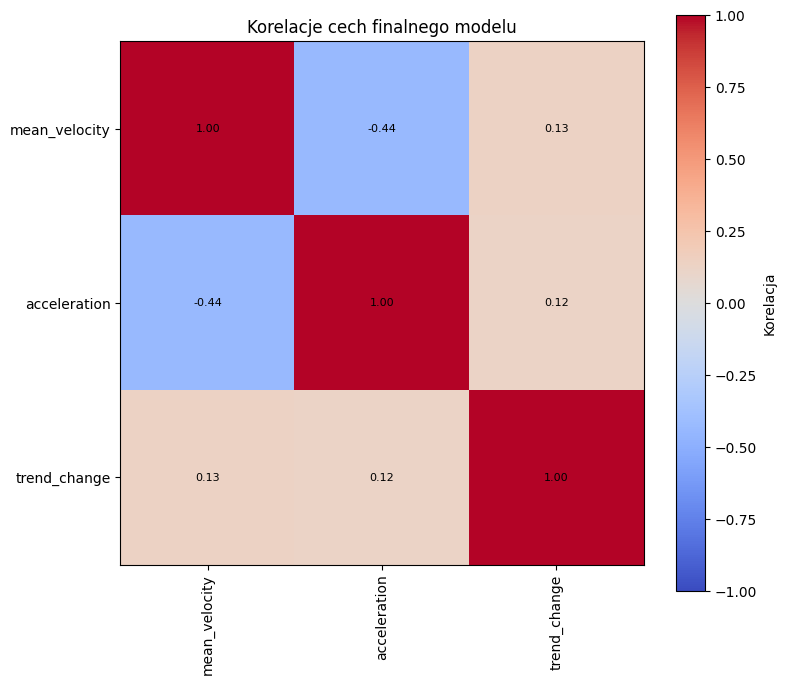

In [29]:
model_features = [
    "mean_velocity",
    "acceleration",
    "trend_change"
]

control_features = [
    "rmse_ts",
    "trend_R2",
    "seasonality"
]

corr_features = model_features
corr = df[corr_features].corr()

plt.figure(figsize=(8, 7))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Korelacja")

plt.xticks(range(len(corr_features)), corr_features, rotation=90)
plt.yticks(range(len(corr_features)), corr_features)

for i in range(len(corr_features)):
    for j in range(len(corr_features)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Korelacje cech finalnego modelu")
plt.tight_layout()
plt.show()


# ETAP 4 — Isolation Forest: wykrywanie nietypowych PS

Isolation Forest jest metodą **uczenia nienadzorowanego**. Nie mamy etykiet „uszkodzony / nieuszkodzony”, dlatego model nie uczy się uszkodzeń.

Model odpowiada na pytanie:

> **Które PS mają nietypową kombinację cech deformacyjnych na tle całego zbioru?**

`anomaly_score` traktujemy jako wynik ciągły: im wyższy, tym bardziej nietypowy punkt.


In [30]:
# Isolation Forest uruchamiamy tylko dla PS z kompletem cech
mask_model = df[model_features].notna().all(axis=1)
X_if = df.loc[mask_model, model_features]

if (~mask_model).any():
    print(f"Ostrzeżenie: pominięto {(~mask_model).sum()} PS z brakami danych.")

iso_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

iso_forest.fit(X_if)

# Odwrócenie znaku: wyższy wynik oznacza bardziej nietypowy PS.
# Wynik przypisujemy po indeksie, żeby trafił do właściwych punktów.
df["anomaly_score"] = np.nan
df.loc[mask_model, "anomaly_score"] = -iso_forest.score_samples(X_if)

Za anomalne przyjmujemy umownie 5% PS o najwyższym anomaly_score. Nie oznacza to, że 5% punktów reprezentuje rzeczywistą anomalną deformację, jest to próg służący do wyboru punktów do dalszej analizy.

In [31]:
threshold = df["anomaly_score"].quantile(0.95)

df["anomaly"] = df["anomaly_score"] >= threshold

print("Próg anomaly_score:", round(threshold, 3))
print(df["anomaly"].value_counts())

Próg anomaly_score: 0.575
anomaly
False    5343
True      282
Name: count, dtype: int64


## Kontrola wyniku

Isolation Forest wskazuje punkty nietypowe na podstawie kombinacji analizowanych cech. Sam wysoki anomaly_score nie oznacza jednak automatycznie anomalnej deformacji. Dlatego sprawdzimy:
1. Czy anomaly_score jest związany z RMSE szeregu czasowego?
2. Jak wyglądają rzeczywiste szeregi czasowe punktów o najwyższym anomaly_score?
3. Czy model wskazuje wyłącznie PS o najbardziej ujemnym mean_velocity?

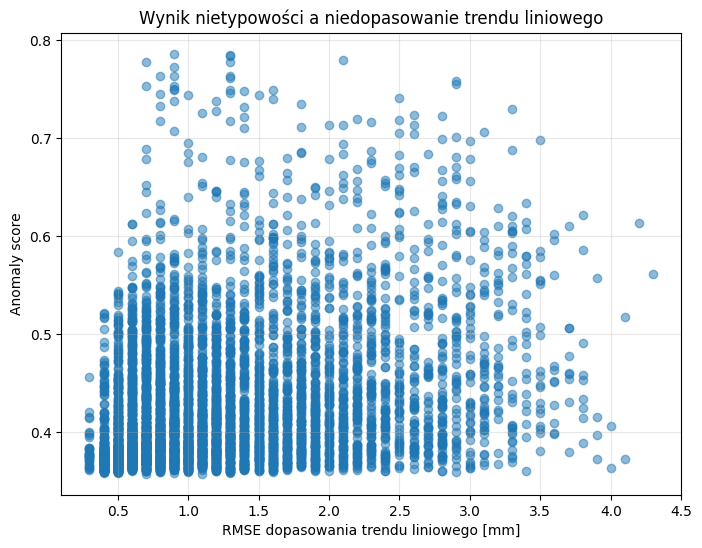

In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["rmse_ts"],
    df["anomaly_score"],
    alpha=0.5
)

plt.xlabel("RMSE dopasowania trendu liniowego [mm]")
plt.ylabel("Anomaly score")
plt.title("Wynik nietypowości a niedopasowanie trendu liniowego")
plt.grid(alpha=0.3)

plt.show()

In [33]:
corr_rmse = df["anomaly_score"].corr(df["rmse_ts"])

print("Korelacja anomaly_score vs RMSE:",
      round(corr_rmse, 3))

Korelacja anomaly_score vs RMSE: 0.297


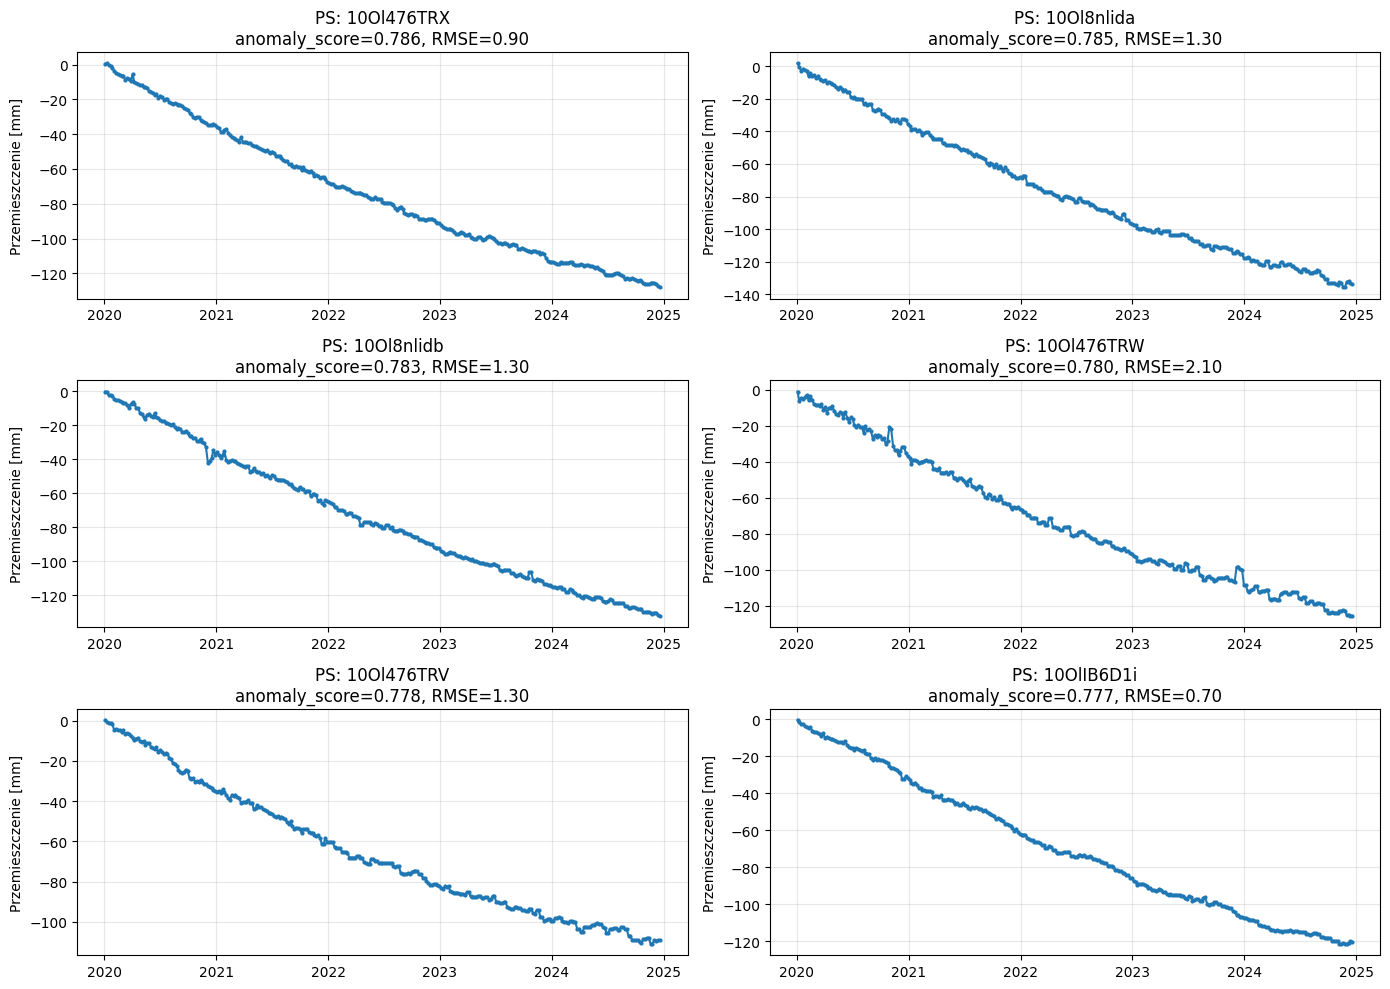

In [34]:
### Kontrola szeregów czasowych punktów o najwyższym wyniku nietypowości

top_anomalies = df.nlargest(6, "anomaly_score")

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_anomalies.iterrows()):

    y = row[date_cols].astype(float).values

    ax.plot(dates, y, marker="o", markersize=2)

    ax.set_title(
        f"PS: {row['pid']}\n"
        f"anomaly_score={row['anomaly_score']:.3f}, "
        f"RMSE={row['rmse_ts']:.2f}"
    )

    ax.set_ylabel("Przemieszczenie [mm]")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
top20_model = df.nlargest(20, "anomaly_score")
top20_velocity = df.nsmallest(20, "mean_velocity")

model_ids = set(top20_model["pid"])
velocity_ids = set(top20_velocity["pid"])

common = model_ids & velocity_ids

print("Wspólne PS w TOP20:", len(common), "/ 20")
print("Udział wspólnych:",
      round(len(common) / 20 * 100, 1), "%")

Wspólne PS w TOP20: 13 / 20
Udział wspólnych: 65.0 %


# ETAP 5 — K-means: typowe rodzaje zachowania

> **Jakie grupy podobnych zachowań deformacyjnych występują w zbiorze?**

In [36]:
# Do K-means przekazujemy ten sam zestaw cech co do Isolation Forest
mask_kmeans = df[model_features].notna().all(axis=1)

X_kmeans = df.loc[
    mask_kmeans,
    model_features
].copy()

print("Liczba wszystkich PS:", len(df))
print("PS wykorzystane przez K-means:", len(X_kmeans))
print("PS pominięte z powodu braków:", (~mask_kmeans).sum())

# Standaryzacja cech
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)

print("Rozmiar danych po skalowaniu:", X_scaled.shape)

Liczba wszystkich PS: 5625
PS wykorzystane przez K-means: 5625
PS pominięte z powodu braków: 0
Rozmiar danych po skalowaniu: (5625, 3)


## Dobór liczby klastrów

Sprawdzamy `k = 2...8`.

- **Inertia / elbow** — szukamy miejsca, po którym dodawanie kolejnych klastrów daje coraz mniejszą poprawę.
- **Silhouette score** — wyższa wartość oznacza lepsze rozdzielenie grup.

Nie wybieramy `k` mechanicznie. Oprócz wykresów klastry powinny mieć sens interpretacyjny.


In [37]:
ks = range(2, 9)
inertias = []
silhouettes = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42) # n_init --> grupowanie wykonywane jest 20 razy z różnymi pozycjami początkowymi
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

results_k = pd.DataFrame({
    "k": list(ks),
    "inertia": inertias,
    "silhouette": silhouettes
})

results_k.round(3)

   k    inertia  silhouette
0  2  11511.704       0.510
1  3   8779.299       0.313
2  4   7713.803       0.317
3  5   6724.583       0.325
4  6   5793.377       0.275
5  7   5064.873       0.292
6  8   4614.355       0.298


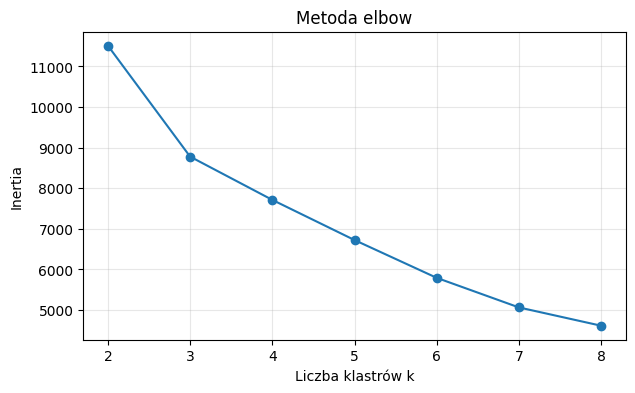

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(results_k["k"], results_k["inertia"], marker="o")
axes[0].set_xlabel("Liczba klastrów k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Metoda elbow")
axes[0].grid(alpha=0.3)

axes[1].plot(results_k["k"], results_k["silhouette"], marker="o")
axes[1].set_xlabel("Liczba klastrów k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Wybierz `k`

Najwyższy silhouette ma `k = 2` (0,51), ale taki podział oddziela jedynie punkty stabilne od osiadających. Dla `k = 3...5` silhouette jest podobny (ok. 0,31–0,33), a na wykresie elbow spadek inertii wyraźnie słabnie po `k = 4`.

Wybieramy **`k = 4`**: podział nadal jest statystycznie poprawny, a klastry dają się sensownie zinterpretować (stabilne, przyspieszające, silne osiadanie, silne przyspieszające osiadanie).

In [39]:
# Wybrana liczba klastrów
k_final = 4

kmeans = KMeans(
    n_clusters=k_final,
    n_init=20,
    random_state=42
)

# K-means wykonujemy tylko dla PS posiadających komplet cech
labels_final = kmeans.fit_predict(X_scaled)

# Najpierw tworzymy pustą kolumnę dla wszystkich PS
df["cluster"] = pd.NA

# Etykiety przypisujemy tylko tym PS,
# które rzeczywiście uczestniczyły w K-means
df.loc[mask_kmeans, "cluster"] = labels_final

# Typ Int64 pozwala przechowywać liczby całkowite oraz brak <NA>
df["cluster"] = df["cluster"].astype("Int64")

print("Liczebność klastrów:")
print(df["cluster"].value_counts(dropna=False).sort_index())

Liczebność klastrów:
cluster
0    1696
1    3076
2     571
3     282
Name: count, dtype: Int64


## Charakterystyka klastrów

Po tej analizie można nadać klastrom opisowe nazwy, np. „regularne osiadanie” czy „zmienne tempo”, jeśli dane rzeczywiście to pokazują.


In [40]:
print("Liczebność klastrów:")
print(df["cluster"].value_counts().sort_index())

cluster_summary = (
    df.groupby("cluster")[model_features + ["rmse_ts", "anomaly_score"]]
      .median()
      .round(3)
)

cluster_summary


Liczebność klastrów:
cluster
0    1696
1    3076
2     571
3     282
Name: count, dtype: Int64


,mean_velocity,acceleration,trend_change,rmse_ts,anomaly_score
cluster,,,,,
0,-1.6,-0.31,-3.293,1.3,0.415
1,-1.3,0.29,1.016,1.0,0.389
2,-10.0,0.81,-0.474,0.9,0.498
3,-8.6,1.82,-6.710,1.4,0.557


### Nazwy klastrów

Na podstawie median cech nadajemy klastrom opisowe nazwy. Numeracja klastrów jest stała dla tych danych i `random_state=42`; po zmianie danych lub parametrów nazwy trzeba sprawdzić ponownie.

In [ ]:
cluster_names = {
    0: "słabe osiadanie, przyspieszające",
    1: "stabilne / słabe osiadanie",
    2: "silne, równomierne osiadanie",
    3: "silne osiadanie, przyspieszające",
}

df["cluster_name"] = df["cluster"].map(cluster_names)

df.groupby(["cluster", "cluster_name"])["pid"].count()

## PCA — wizualizacja klastrów w dwóch wymiarach

PCA służy tylko do pokazania wielowymiarowych danych na płaszczyźnie. Kompresuje informację zawartą w wielu cechach do dwóch nowych wymiarów, dzięki czemu możemy zwizualizować wielowymiarowe dane na płaszczyźnie.



Wyjaśniona wariancja PC1 + PC2: 83.2 %


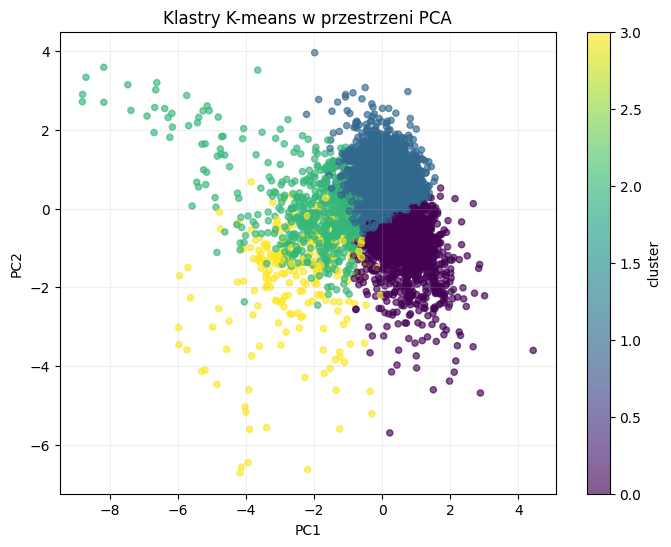

In [41]:
# PCA wykonujemy na tych samych PS,
# które zostały wykorzystane w K-means

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Tworzymy puste kolumny dla wszystkich PS
df["PC1"] = np.nan
df["PC2"] = np.nan

# Wyniki PCA przypisujemy tylko punktom,
# które uczestniczyły w K-means
df.loc[mask_kmeans, "PC1"] = X_pca[:, 0]
df.loc[mask_kmeans, "PC2"] = X_pca[:, 1]

print(
    "Wyjaśniona wariancja PC1 + PC2:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        1
    ),
    "%"
)

# Do wykresu bierzemy tylko PS posiadające wynik PCA i klaster
df_pca = df.loc[mask_kmeans].copy()

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df_pca["PC1"],
    df_pca["PC2"],
    c=df_pca["cluster"].astype(int),
    alpha=0.65,
    s=20
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Klastry K-means w przestrzeni PCA")

plt.colorbar(
    scatter,
    label="cluster"
)

plt.grid(alpha=0.2)
plt.show()

## Przykładowe szeregi z każdego klastra



KLASTER 0


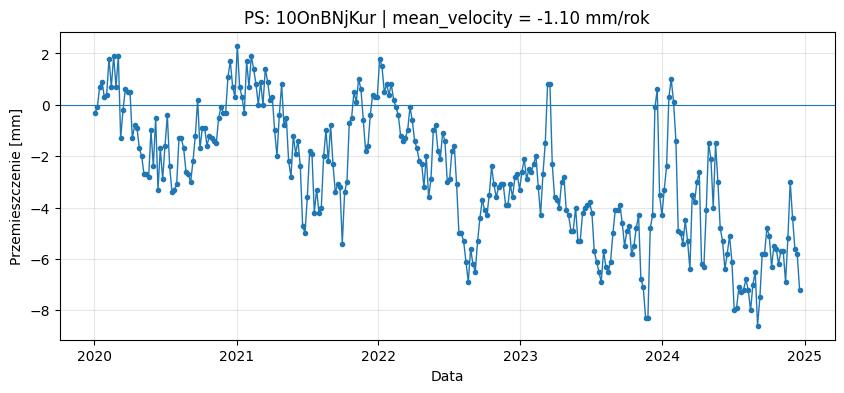

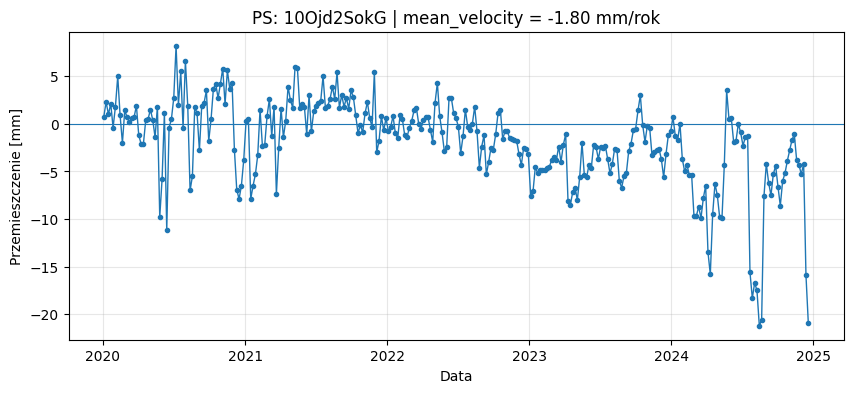

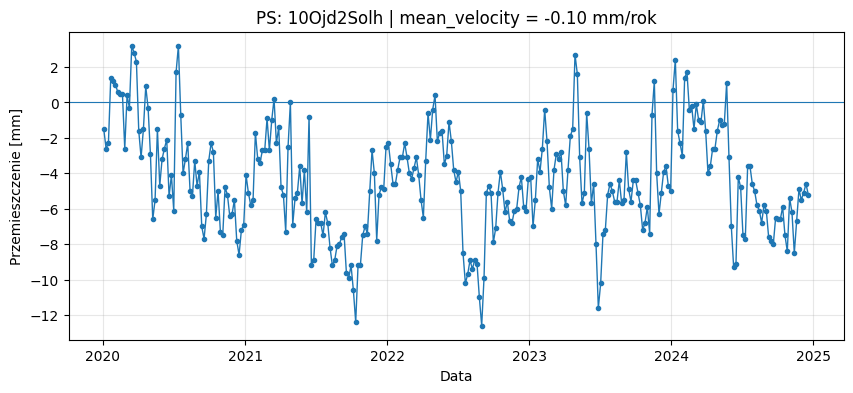


KLASTER 1


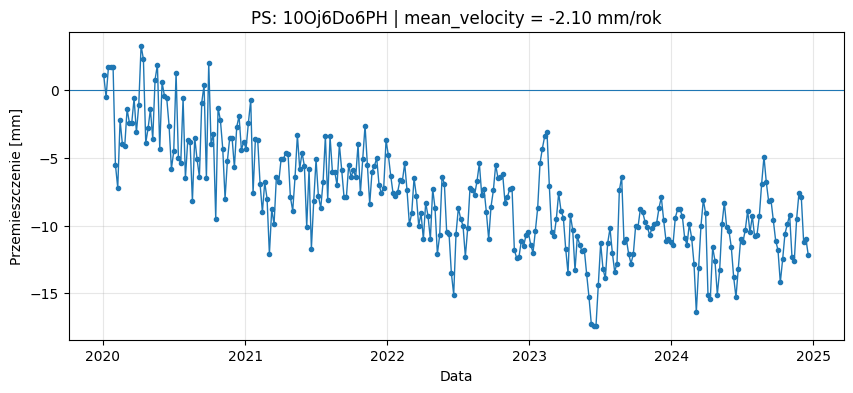

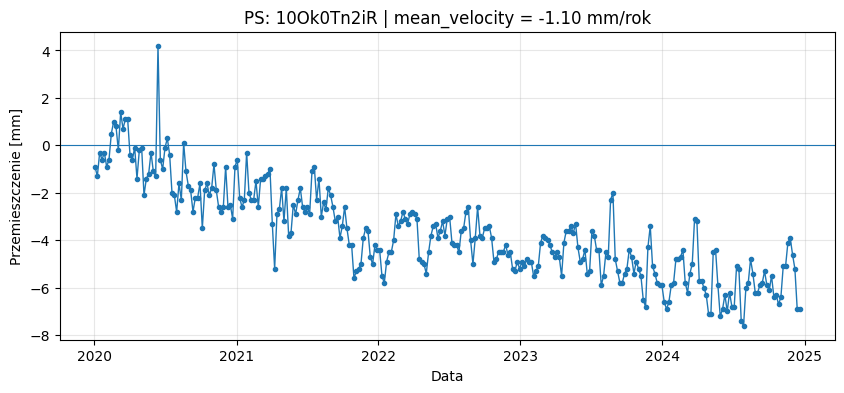

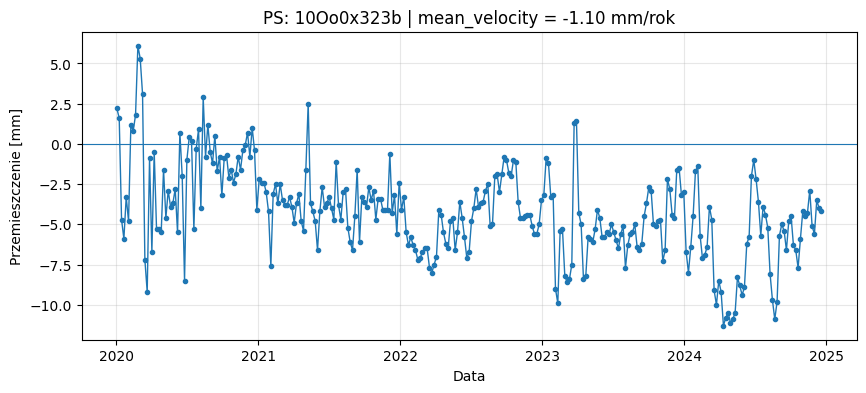


KLASTER 2


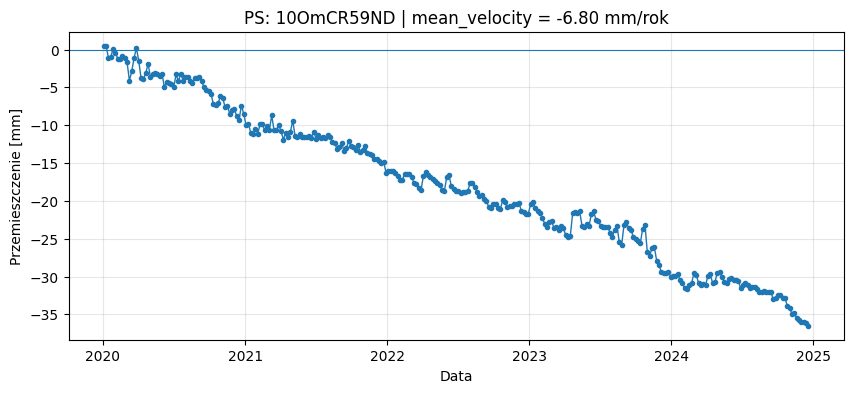

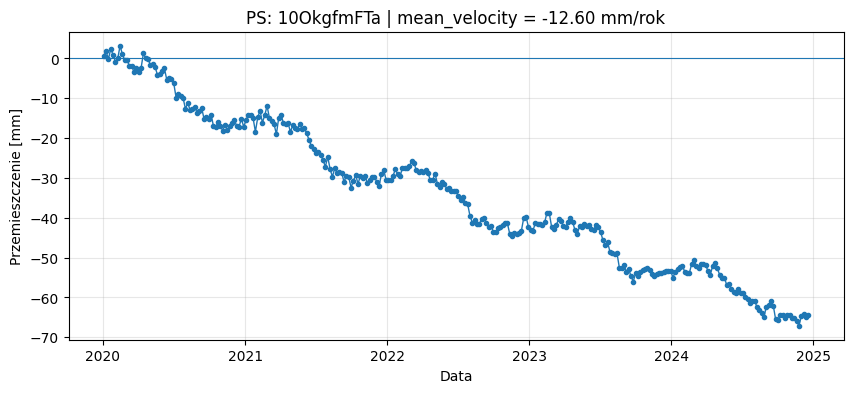

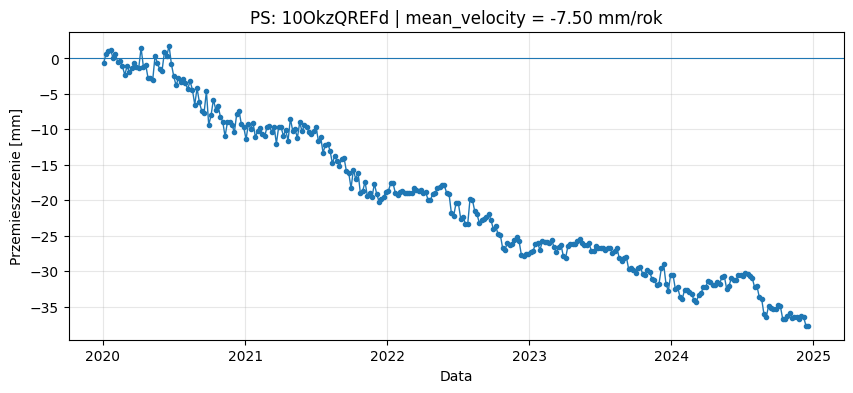


KLASTER 3


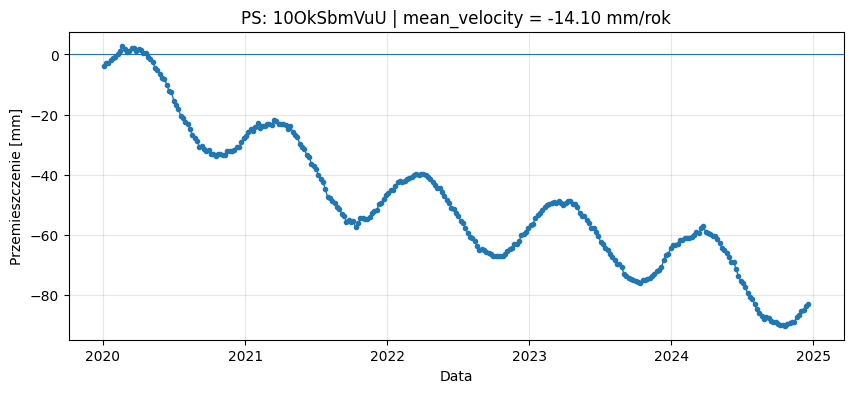

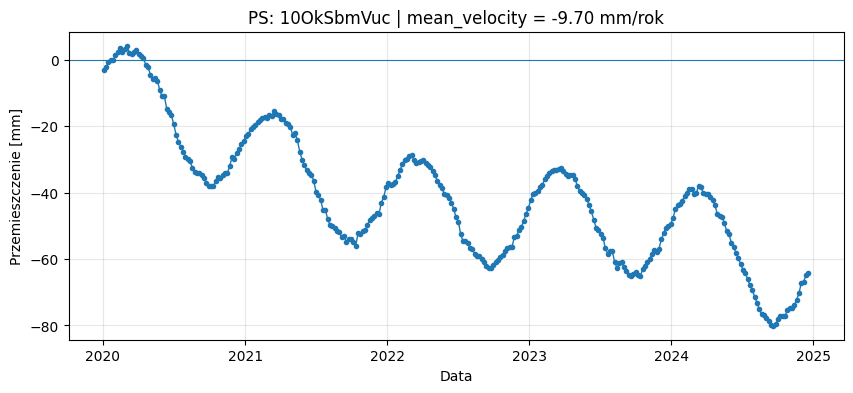

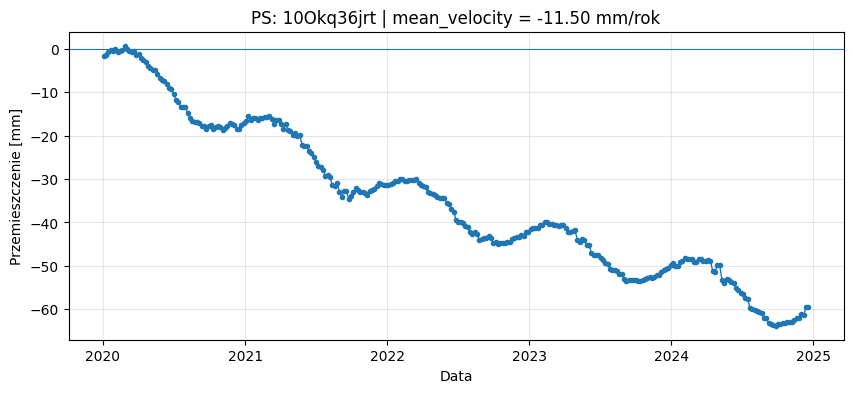

In [42]:
# Analizujemy tylko PS, które mają przypisany klaster
df_clustered = df.dropna(subset=["cluster"]).copy()

for cluster_id in sorted(df_clustered["cluster"].unique()):

    print("\nKLASTER", cluster_id)

    cluster_points = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    sample = cluster_points.sample(
        n=min(3, len(cluster_points)),
        random_state=42
    )

    for pid in sample["pid"]:
        plot_ps(pid)

# ETAP 6 — Zestawienie wyników Isolation Forest i K-means

Obie metody opisują inne aspekty danych:

- `anomaly_score` — **jak nietypowy** jest PS,
- `cluster` — **do jakiego typu zachowania** jest najbardziej podobny.

Sprawdzamy więc, czy nietypowe PS koncentrują się w określonych klastrach.


In [43]:
cluster_model_summary = (
    df.groupby("cluster")
    .agg(
        n_PS=("pid", "count"),
        median_velocity=("mean_velocity", "median"),
        median_acceleration=("acceleration", "median"),
        median_trend_change=("trend_change", "median"),
        median_anomaly_score=("anomaly_score", "median"),
        max_anomaly_score=("anomaly_score", "max"),
        median_rmse=("rmse_ts", "median")
    )
    .round(3)
)

cluster_model_summary

,n_PS,median_velocity,median_acceleration,median_trend_change,median_anomaly_score,max_anomaly_score,median_rmse
cluster,,,,,,,
0,1696,-1.6,-0.31,-3.293,0.415,0.706,1.3
1,3076,-1.3,0.29,1.016,0.389,0.668,1.0
2,571,-10.0,0.81,-0.474,0.498,0.786,0.9
3,282,-8.6,1.82,-6.710,0.557,0.758,1.4


In [44]:
cluster_anomalies = df.groupby("cluster").agg(
    n_PS=("pid", "count"),
    n_anomalies=("anomaly", "sum"),
    median_anomaly_score=("anomaly_score", "median")
)

cluster_anomalies["percent_anomalies"] = (
    cluster_anomalies["n_anomalies"]
    / cluster_anomalies["n_PS"]
    * 100
).round(1)

cluster_anomalies

,n_PS,n_anomalies,median_anomaly_score,percent_anomalies
cluster,,,,
0,1696,71,0.415301,4.2
1,3076,15,0.388685,0.5
2,571,78,0.498107,13.7
3,282,118,0.557488,41.8


# ETAP 7 — Eksport do QGIS

Eksportujemy danych do QGIS.

In [45]:
export_cols = (
    [
        "pid",
        "easting",
        "northing",
        "mean_velocity",
        "acceleration",
        "seasonality",
        "rmse_ts",
        "trend",
        "trend_R2",
    ]
    + yearly_trend_cols
    + [
        "annual_trend_std",
        "baseline_velocity",
        "recent_velocity",
        "trend_change",
        "anomaly_score",
        "anomaly",
        "cluster",
        "cluster_name",
    ]
)

# Kontrola obecności wymaganych kolumn
missing_cols = [
    col for col in export_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Brakujące kolumny: {missing_cols}"
    )

export = df[export_cols].copy()

# 0/1 zamiast True/False — łatwiej filtrować i stylizować w QGIS
export["anomaly"] = export["anomaly"].astype(int)

export.to_csv(
    "EGMS_Thessaloniki_results.csv",
    index=False,
    encoding="utf-8"
)

print(
    "Zapisano wyniki PS: "
    "EGMS_Thessaloniki_results.csv"
)

Zapisano wyniki PS: EGMS_Thessaloniki_results.csv
